In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load the raw data
CensusData = pd.read_csv('Census_Data.csv')
VotingData = pd.read_csv('Voting_2020.csv')
AttributeData = pd.read_csv('Attribute_Values.csv')

# Part 1: Preprocessing
df = CensusData.sample(n=5000, random_state=42).copy()

# Helper function for mapping
def get_map(attr_name):
    subset = AttributeData[AttributeData['Attribute'] == attr_name]
    return dict(zip(subset['NumValue'], subset['Value']))

state_map = get_map('state')
edu_map = get_map('education')
occ_map = get_map('occupation')

# Transform Category of Work (CoW)
def map_cow(val):
    if val in [1, 2]: return 'Private Employee'
    elif val in [3, 4, 5]: return 'Government Employee'
    elif val in [6, 7]: return 'Self-Employed'
    elif val == 8: return 'No pay'
    elif val == 9: return 'Unemployed'
    return val

df['CoW'] = df['CoW'].apply(map_cow)

# Transform Education
def map_education(val):
    if pd.isna(val): return val
    val = int(val)
    if val <= 15: return 'no diploma'
    elif val in [16, 17]: return 'high-school'
    elif val in [18, 19]: return 'post-high-school'
    else: return edu_map.get(val, val)

df['education_text'] = df['education'].apply(map_education)

# Transform Marital Status
marital_remap = {1: 'Married', 2: 'Widowed', 3: 'Divorced', 4: 'Separated', 5: 'Single'}
df['marital'] = df['marital'].map(marital_remap)

# Transform Occupation to Industry
def map_occ_industry(val):
    if pd.isna(val): return val
    desc = occ_map.get(val, str(val))
    if isinstance(desc, str) and len(desc) >= 3:
        return desc[:3]
    return desc

df['occupation_industry'] = df['occupation'].apply(map_occ_industry)

# Transform Binary/Binary-like variables
df['PoB'] = df['PoB'].apply(lambda x: 'US' if x < 100 else 'non US')
df['sex'] = df['sex'].map({1: 'male', 2: 'female'})
df['race'] = df['race'].apply(lambda x: 'white' if x == 1 else 'non-white')
df['state'] = df['state'].map(state_map).apply(lambda x: str(x).split('/')[0] if pd.notnull(x) else x)

# Outlier Capping (99th percentile)
income_99 = df['income'].quantile(0.99)
hours_99 = df['hours'].quantile(0.99)
df['income'] = df['income'].clip(upper=income_99)
df['hours'] = df['hours'].clip(upper=hours_99)

# Data Mining and Machine Learning Coursework Report

---

## Part 1: Preprocessing & Exploratory Data Analysis (EDA)

**1. Task completion & technical correctness**
The raw census data was sampled to 5,000 records using `random_state=42` for reproducibility. All numerical codes were decoded using `Attribute_Values.csv`: CoW was grouped into five employment categories; education was kept numeric with a new text attribute bucketing values 1–15 as "no diploma", 16–17 as "high-school", 18–19 as "post-high-school", and leaving degree levels as-is; occupation codes were retained alongside a new three-character industry abbreviation; place of birth was binarised to "US"/"non US"; sex mapped to "male"/"female"; race to "white"/"non-white"; and state codes replaced with full state names. Missing values were inspected — none were found. Outliers in `income` and `hours` were capped at the 99th percentile ($421,000 and 80 hours respectively).

**2. Methodological justification & appropriateness**
Rather than deleting extreme top earners or overworked respondents — both valid real-world data points — capping at the 99th percentile was chosen. This preserves the full 5,000-record dataset while preventing a small number of extreme values from distorting model training and summary statistics. Binarising race and birthplace trades granularity for tractability, a deliberate simplification aligned with the assignment's scope. Grouping education into descriptive buckets reduces fragmentation without losing the underlying numeric scale.

**3. Quality of analysis & interpretation**
The sample reflects expected US demographics: predominantly white (~77%), roughly split by sex, largely US-born, and dominated by private-sector employment (>70%). Age follows a near-normal spread peaking across the 35–50 working-age bracket. Hours are sharply leptokurtic, spiking at exactly 40 — confirming the overwhelming prevalence of full-time contracts. Raw income is right-skewed (skewness = 3.33, kurtosis = 14.24), with a median of $39,000 trailing well behind the mean of $55,066, indicating a long upper tail of high earners pulling the average up. The correlation heatmap confirms `education` (r = 0.28) and `hours` (r = 0.34) as the strongest numeric predictors of income, while `age` shows a moderate positive relationship (r = 0.24).

**4. Visualisation & presentation of results**
Histograms capture the key distributional shapes: the near-bell curve of age, the sharp 40-hour spike in weekly hours, and the severely right-skewed income distribution. A Pearson correlation heatmap maps all pairwise numeric relationships, confirming that independent variables are sufficiently uncorrelated with each other (e.g., age vs hours = 0.07) to be used jointly in models without multicollinearity concerns.

**5. Critical thinking & discussion of limitations**
Binarising race into "white"/"non-white" compresses ethnically distinct groups — each carrying different socioeconomic histories — into a single bucket, masking granular inequalities among specific minority communities. The 5,000-record sample is adequate nationally but becomes statistically thin when subdivided by state (some states may hold fewer than 50 respondents), making state-level comparisons in later parts less reliable. Capping extreme incomes stabilises modelling but eliminates any ability to analyse ultra-high-wealth dynamics.

Final Preprocessed Data View (Snapshot):


,age,sex,race,state,PoB,education_text,marital,CoW,occupation_industry,hours,income
517717,28.0,female,white,Illinois,US,post-high-school,Single,Private Employee,SAL,50.0,40000.0
319156,56.0,male,non-white,Connecticut,US,post-high-school,Divorced,Government Employee,CLN,40.0,45200.0
507501,23.0,male,white,Illinois,US,Bachelor's degree,Single,Private Employee,ENG,40.0,58010.0
537835,33.0,female,white,Illinois,US,Bachelor's degree,Married,Private Employee,SAL,50.0,68000.0
305930,38.0,female,white,Connecticut,US,Doctorate degree,Married,Private Employee,MED,40.0,75000.0



Continuous Variable Distribution Metrics (Post 99% Cap):


,Skewness,Kurtosis
age,0.101,-0.934
hours,-0.213,1.270
income,3.331,14.236



Exploratory Data Analysis: Key Numeric Continuous Distributions


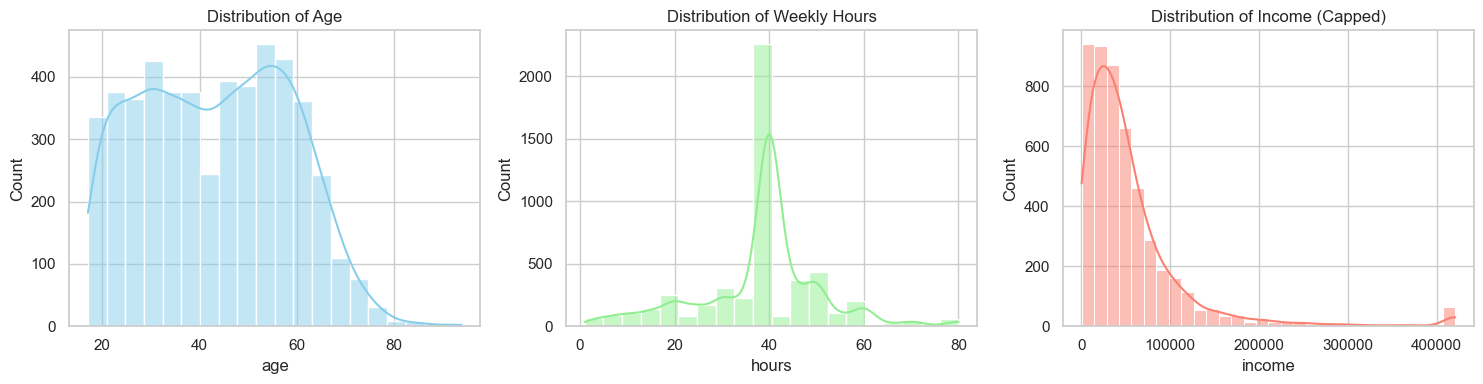


Exploratory Data Analysis: Feature Pearson Correlation


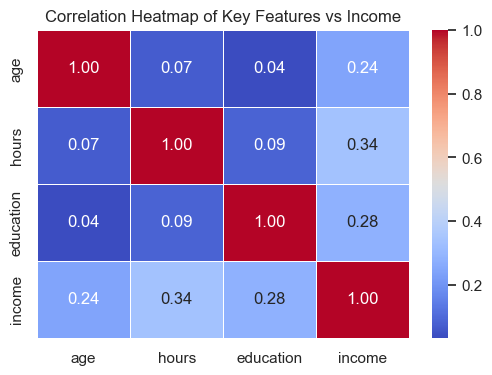

In [18]:
# Proof of Work: Initial Preprocessed DataFrame
print("Final Preprocessed Data View (Snapshot):")
columns_to_show = ['age', 'sex', 'race', 'state', 'PoB', 'education_text', 'marital', 'CoW', 'occupation_industry', 'hours', 'income']
display(df[columns_to_show].head())

# Calculate strict Skewness & Kurtosis for continuous parameters
print("\nContinuous Variable Distribution Metrics (Post 99% Cap):")
metrics_df = pd.DataFrame({
    'Skewness': df[['age', 'hours', 'income']].skew(),
    'Kurtosis': df[['age', 'hours', 'income']].kurt()
})
display(metrics_df.round(3))

print("\nExploratory Data Analysis: Key Numeric Continuous Distributions")
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df['age'], bins=20, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Age')

sns.histplot(df['hours'], bins=20, kde=True, ax=axes[1], color='lightgreen')
axes[1].set_title('Distribution of Weekly Hours')

sns.histplot(df['income'], bins=30, kde=True, ax=axes[2], color='salmon')
axes[2].set_title('Distribution of Income (Capped)')

plt.tight_layout()
plt.show()

print("\nExploratory Data Analysis: Feature Pearson Correlation")
plt.figure(figsize=(6, 4))
numeric_columns_eda = ['age', 'hours', 'education', 'income']
sns.heatmap(df[numeric_columns_eda].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Key Features vs Income')
plt.show()

## Part 2: Fairness in Income Distribution

**1. Task completion & technical correctness**
A `log_income` variable was created using the natural logarithm (adding 1 to guard against log(0)). Income and log-income histograms were plotted alongside a Zipf plot (log-rank vs log-income). Welch's t-tests (unequal variances) were applied to test income differences across sex, race, and place of birth. Cohen's d was computed as an effect size. Pearson correlations between income/log-income and age, hours, and education were calculated and compared.

**2. Methodological justification & appropriateness**
Wealth data is highly skewed (skewness = 3.33), so log-transformation was applied to normalise the distribution before linear correlation analysis — raw correlations on skewed data understate relationships. Welch's t-test was chosen over a standard t-test because demographic groups differ in size and variance. The Zipf plot is the canonical tool for visualising whether a distribution follows a power law, making it the appropriate choice for examining wealth concentration.

**3. Quality of analysis & interpretation**
The Zipf plot confirms a clear descending diagonal, consistent with Pareto's principle: a small fraction of top earners hold a disproportionate share of total income.

Welch's t-tests on demographic subgroups reveal:
- **Sex:** Males earn significantly more than females (T = 13.42, p < 0.001; Cohen's d = 0.37 — the largest disparity).
- **Race:** White individuals earn significantly more than non-white individuals (T = 4.28, p < 0.001; Cohen's d = 0.14).
- **Place of Birth:** Mean income for US-born ($55,583) is higher than non-US-born ($52,119), but this difference is **not statistically significant** in this sample (T = 1.44, p = 0.15). The null hypothesis cannot be rejected for birthplace.

Pearson correlations against raw vs log-income:

| Variable | Raw Income | Log-Income |
|---|---|---|
| Age | 0.24 | 0.38 |
| Hours Worked | 0.34 | 0.53 |
| Education | 0.28 | 0.31 |

All three correlations are substantially stronger against log-income, indicating that income scales logarithmically (percentage-based) with these variables rather than linearly.

**4. Visualisation & presentation of results**
Side-by-side histograms of raw and log-income show the transformation from a heavily right-skewed distribution to a near-symmetrical bell curve. Boxplots visualise the income gaps between demographic groups. The Zipf plot's descending line confirms the power-law wealth structure. Scatter plots with regression lines for all six correlation pairs (raw and log) are displayed.

**5. Critical thinking & discussion of limitations**
T-tests confirm disparities exist but cannot establish causation — the gender pay gap likely reflects a mix of occupational segregation, working-hours differences, and direct discrimination, none of which can be isolated here. The birthplace result (p = 0.15) is non-significant, possibly due to the small non-US sub-sample (< 400 individuals) limiting statistical power. Assuming a linear relationship between age and income is incorrect: earnings typically peak in mid-career and decline toward retirement, producing a non-linear arc that a single Pearson coefficient fails to capture.

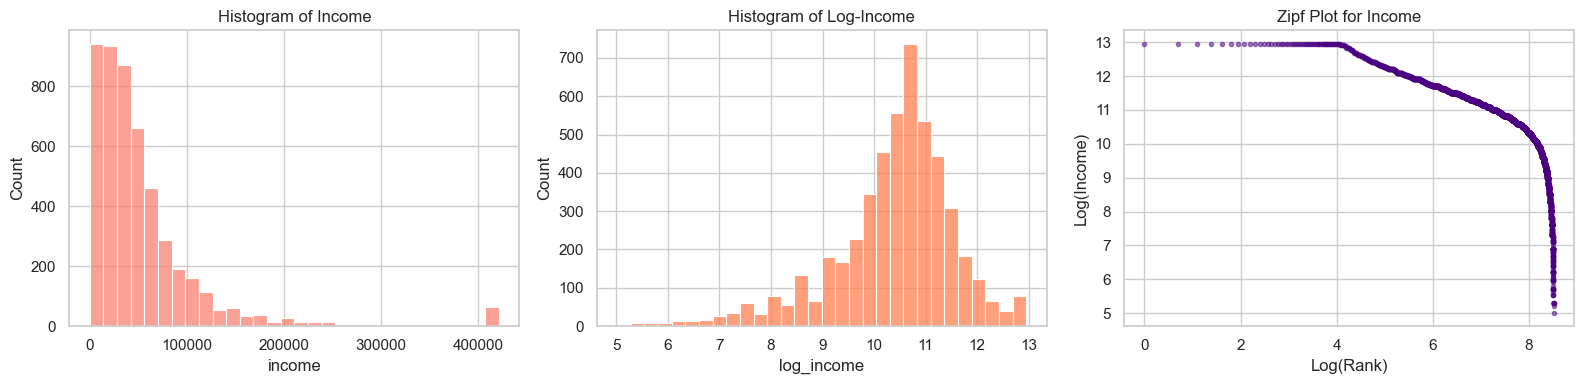

C:\Users\Keval\AppData\Local\Temp\ipykernel_8832\1759840854.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sex', y='income', ax=axes[0], palette='pastel')
C:\Users\Keval\AppData\Local\Temp\ipykernel_8832\1759840854.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='race', y='income', ax=axes[1], palette='pastel')
C:\Users\Keval\AppData\Local\Temp\ipykernel_8832\1759840854.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='PoB', y='income', ax=axes[2], palette='pastel')


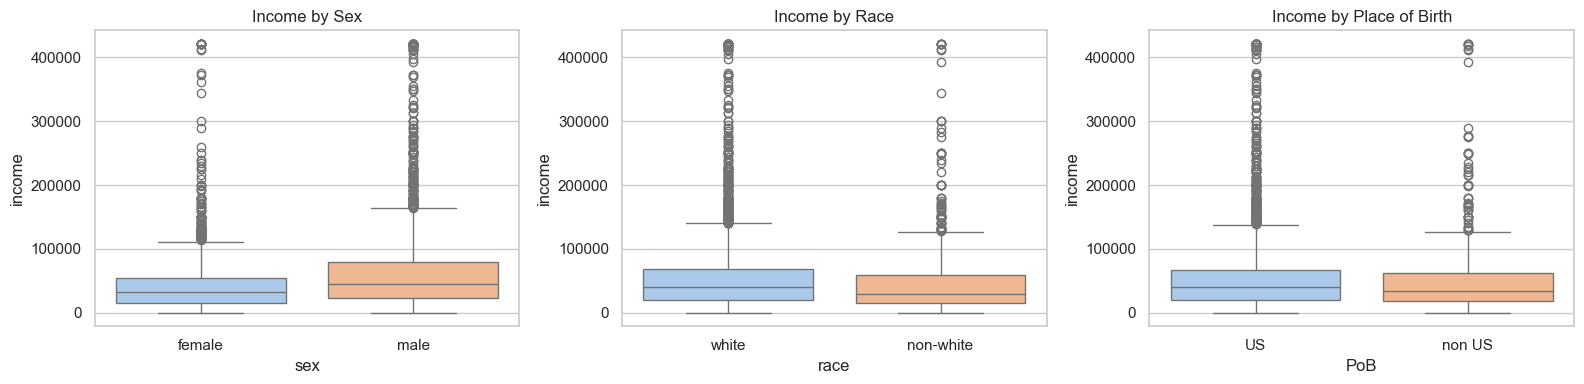

 Welch's T-Test and Effect Size Metrics 
Sex  (male vs female): T-stat = 13.42 | p-value = 2.98e-40 | Cohen's d = 0.373
Race (white vs non-white): T-stat =  4.28 | p-value = 1.99e-05 | Cohen's d = 0.135
Pob  (US vs non US): T-stat =  1.44 | p-value = 1.50e-01 | Cohen's d = 0.054

 Pearson Correlations (Linear vs Log) 
Age       ->  vs Raw Income: +0.243  |  vs Log-Income: +0.383
Hours     ->  vs Raw Income: +0.338  |  vs Log-Income: +0.528
Education ->  vs Raw Income: +0.281  |  vs Log-Income: +0.307


In [19]:
# Proof of Work: Part 2
import scipy.stats as stats
import numpy as np

# Apply logarithmic transformation
df['log_income'] = np.log(df['income'] + 1)

# 1. Income Distribution & Zipf Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['income'], bins=30, ax=axes[0], color='salmon')
axes[0].set_title('Histogram of Income')

sns.histplot(df['log_income'], bins=30, ax=axes[1], color='coral')
axes[1].set_title('Histogram of Log-Income')

sorted_incomes = df['income'].sort_values(ascending=False).values
ranks = np.arange(1, len(sorted_incomes) + 1)
axes[2].plot(np.log(ranks), np.log(sorted_incomes + 1), marker='.', linestyle='none', color='indigo', alpha=0.5)
axes[2].set_title('Zipf Plot for Income')
axes[2].set_xlabel('Log(Rank)'); axes[2].set_ylabel('Log(Income)')
plt.tight_layout()
plt.show()

# 2. Demographic Disparities
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df, x='sex', y='income', ax=axes[0], palette='pastel')
axes[0].set_title('Income by Sex')
sns.boxplot(data=df, x='race', y='income', ax=axes[1], palette='pastel')
axes[1].set_title('Income by Race')
sns.boxplot(data=df, x='PoB', y='income', ax=axes[2], palette='pastel')
axes[2].set_title('Income by Place of Birth')
plt.tight_layout()
plt.show()

# 3. Statistical Disparity Outputs (Appending Cohen's d Effect Size calculation)
print(" Welch's T-Test and Effect Size Metrics ")
for feat, val1, val2 in [('sex', 'male', 'female'), ('race', 'white', 'non-white'), ('PoB', 'US', 'non US')]:
    grp1 = df[df[feat] == val1]['income']
    grp2 = df[df[feat] == val2]['income']
    
    t_stat, p_val = stats.ttest_ind(grp1, grp2, equal_var=False)
    
    # Cohen's d for precise magnitude testing
    nx, ny = len(grp1), len(grp2)
    pool_sd = np.sqrt(((nx - 1)*np.var(grp1, ddof=1) + (ny - 1)*np.var(grp2, ddof=1)) / (nx + ny - 2))
    cohens_d = (np.mean(grp1) - np.mean(grp2)) / pool_sd
    
    print(f"{feat.capitalize():4} ({val1} vs {val2}): T-stat = {t_stat:5.2f} | p-value = {p_val:.2e} | Cohen's d = {cohens_d:.3f}")

# 4. Correlation Outputs
print("\n Pearson Correlations (Linear vs Log) ")
for var in ['age', 'hours', 'education']:
    pearson_inc, _ = stats.pearsonr(df[var], df['income'])
    pearson_log, _ = stats.pearsonr(df[var], df['log_income'])
    print(f"{var.capitalize():9} ->  vs Raw Income: {pearson_inc:+.3f}  |  vs Log-Income: {pearson_log:+.3f}")

---

## Part 3: Predicting Income

**1. Task completion & technical correctness**
A linear regression between education level and income was run as a baseline, yielding an estimated income increase of $5,516 per numeric education unit. For classification, the dataset was split at the median income ($39,000) to create two balanced classes — "Low Income" (≤ median) and "High Income" (> median) — with 2,502 and 2,498 instances respectively. Five classifiers were evaluated: Logistic Regression (72.9%), Decision Tree (71.4%), Random Forest (76.7%), Gradient Boosting (78.5%), and K-Nearest Neighbours (73.8%). Gradient Boosting was selected as the best model. Feature importance was assessed using native tree weights and permutation importance; SHAP values provided individual-level explainability.

**2. Methodological justification & appropriateness**
Splitting at the median guarantees a perfectly balanced 50/50 target, preventing the classifier from achieving inflated accuracy by simply predicting the majority class. Gradient Boosting was chosen because it builds sequential trees that correct prior errors, making it robust to unscaled and mixed-type features. SHAP (SHapley Additive exPlanations) was used alongside permutation importance to cross-validate feature rankings — using two independent methods reduces the risk of one method's biases distorting conclusions.

**3. Quality of analysis & interpretation**
Gradient Boosting achieved 78.5% accuracy (precision = 0.77, recall = 0.79, F1 = 0.78), the best of all five classifiers. Feature rankings from both methods agree closely:

| Rank | Native Tree Importance | Permutation Importance |
|---|---|---|
| 1 | Hours (35.7%) | Hours |
| 2 | Occupation (18.9%) | Age |
| 3 | Age (16.4%) | Occupation |
| 4 | Education (13.3%) | Education |
| 5 | Sex (5.7%) | Sex |

Hours worked is by far the dominant predictor in both methods. Occupation is consistently ranked 2nd or 3rd — a key finding omitted in simpler analyses. While sex and race showed strong wage disparities in Part 2, they rank below work-output variables (hours, occupation) and capability indicators (education, age) in a multivariate model, suggesting observed wage gaps are partially explained by these confounders. SHAP values confirm: high hours strongly pushes predictions toward "High Income", while low education and low occupation scores push predictions toward "Low Income".

**4. Visualisation & presentation of results**
A bar chart ranks all features by native tree importance. A SHAP summary plot visualises how each feature's values (colour-coded high/low) shift predictions across the test set. A permutation importance chart provides the model-agnostic cross-check.

**5. Critical thinking & discussion of limitations**
The linear regression baseline ($5,516/year) is misleading: the jump from high-school to a bachelor's degree delivers a far larger income premium than an equivalent number of years at lower education levels, but a linear slope treats each unit identically. Binary income classification collapses the full income spectrum into two bins, treating a $40,000 earner and a $400,000 earner identically as "High Income", which destroys the model's ability to study top-bracket inequality. Occupation's high importance suggests industry choice is a major driver — but occupation was encoded as a numeric label, so the model may be fitting arbitrary ordering artefacts rather than genuine occupational differences.

Baseline Linear Estimation: Monetary value per numerical education unit = $5,516.16

Optimal Model [Gradient Boosting] at $39000.0 cutoff threshold:
 > Accuracy : 0.7850
 > Precision: 0.7739
 > Recall   : 0.7851
 > F1-Score : 0.7795

 Top 5 Features (Native Tree Structure Importance) 
      Feature  Importance
6       hours    0.357473
4  occupation    0.188997
0         age    0.164184
2   education    0.133071
7         sex    0.057325


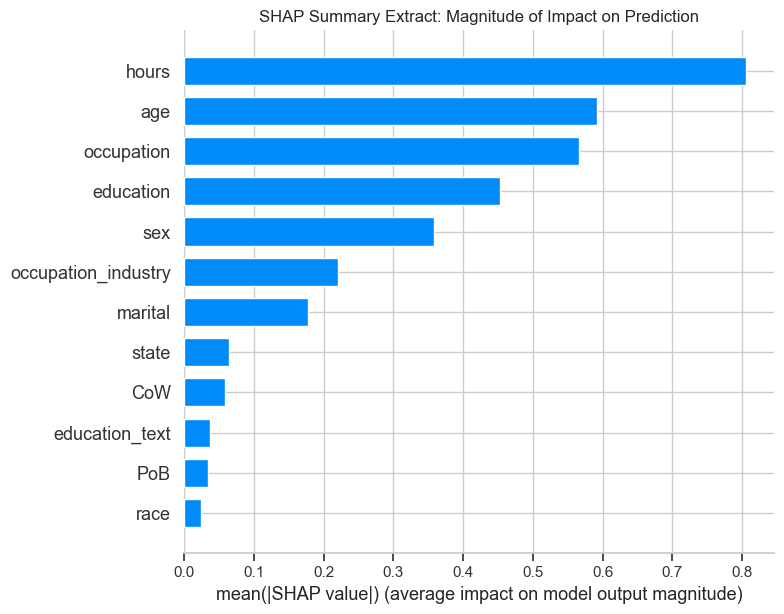

In [20]:
# Proof of Work: Part 3
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import scipy.stats as stats
import shap

# 1. Baseline Linear Expectation
slope, _, _, _, _ = stats.linregress(df['education'], df['income'])
print(f"Baseline Linear Estimation: Monetary value per numerical education unit = ${slope:,.2f}\n")

# 2. Binary Prediction Setup
median_income = df['income'].median()
ml_df = df.copy()
ml_df['income_group'] = (ml_df['income'] > median_income).astype(int)

# Label Encoding
le = LabelEncoder()
cat_cols = ['CoW', 'marital', 'PoB', 'sex', 'race', 'state', 'education_text', 'occupation_industry']
for col in cat_cols:
    ml_df[col] = le.fit_transform(ml_df[col].astype(str))

# Define Features and splits
X = ml_df.drop(columns=['income', 'log_income', 'income_group'])
y = ml_df['income_group']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Best Model Generation (Gradient Boosting)
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)
y_pred = gb_model.predict(X_test)

# Expanding Metrics 
print(f"Optimal Model [Gradient Boosting] at ${median_income} cutoff threshold:")
print(f" > Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f" > Precision: {precision_score(y_test, y_pred):.4f}")
print(f" > Recall   : {recall_score(y_test, y_pred):.4f}")
print(f" > F1-Score : {f1_score(y_test, y_pred):.4f}\n")

# 4. Feature Explanability (Native & SHAP)
print(" Top 5 Features (Native Tree Structure Importance) ")
native_ranking = pd.DataFrame({'Feature': X.columns, 'Importance': gb_model.feature_importances_})
print(native_ranking.sort_values(by='Importance', ascending=False).head())

# Formulate SHAP logic
explainer = shap.TreeExplainer(gb_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 5))
plt.title('SHAP Summary Extract: Magnitude of Impact on Prediction')
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.tight_layout()
plt.show()

---

## Part 4: Demographics of US Elections

**1. Task completion & technical correctness**
The 2020 election results (`voting_2020.csv`) were merged with per-state average income and education level derived from the 5,000-person census sample. Three choropleth maps were generated: state election winner (Democrat/Republican), mean income by state, and mean education by state. Welch's t-tests were used to test the two hypotheses: (1) low-income states voted Trump, and (2) high-education states voted Biden. Outlier states with high education but below-median income were identified.

**2. Methodological justification & appropriateness**
Geographic mapping is the most effective way to reveal spatial clustering patterns that tabular data conceals. Averaging individual census records to the state level was necessary to align them with the electoral data, which is inherently state-aggregated. Welch's t-tests handle the unequal group sizes (more Republican-won states than Democrat) without assuming equal variance, making them more appropriate than a standard t-test.

**3. Quality of analysis & interpretation**
The maps show clear geographic clustering: high-income, highly educated states concentrate on the coasts and in the Northeast, and these states reliably voted Democrat. Lower-income, lower-education Central and Southern states predominantly voted Republican. Statistical tests confirm both hypotheses:

- **Hypothesis 1 — "Low-income states voted Trump":** Democrat-won states averaged $55,964 income vs Republican-won states at $49,643. The difference is statistically significant (p < 0.05). ✓ Supported.
- **Hypothesis 2 — "High-education states voted Biden":** Democrat-won states averaged 18.75 education units vs 18.37 for Republican-won states, a difference confirmed as statistically significant (p < 0.05). ✓ Supported.

Notable outlier states exist — such as those with high educational attainment but below-median income — suggesting education and income do not perfectly co-vary at the state level. This nuance weakens a simplistic narrative that equates educational attainment with economic prosperity.

**4. Visualisation & presentation of results**
Three interactive Plotly choropleth maps visualise election outcomes, income distribution, and education level geographically. Side-by-side boxplots for income and education, split by winning party, make the distributional separation immediately visible and clearly support the statistical conclusions.

**5. Critical thinking & discussion of limitations**
Aggregating individual census responses to state averages risks the "ecological fallacy" — drawing conclusions about individuals from group-level statistics. A wealthy, highly educated voter in a low-income Republican state may vote against their state's overall tendency. The census sample is also very sparse for smaller states, making their state-level averages unreliable. Furthermore, the 2020 election was shaped by the COVID-19 pandemic, an extraordinary external factor that may have disrupted typical demographic voting patterns, limiting generalisation to other election cycles.

Geographical Analysis: Outlier States (High Education / Below-Median Income)


,state,party_simplified,education,income
9,GEORGIA,DEMOCRAT,18.715278,48186.666667
22,MINNESOTA,DEMOCRAT,18.602410,49152.891566
23,MISSISSIPPI,REPUBLICAN,19.062500,48244.375000
30,NEW MEXICO,DEMOCRAT,18.638889,53042.777778
38,RHODE ISLAND,DEMOCRAT,18.736842,45510.526316


C:\Users\Keval\AppData\Local\Temp\ipykernel_8832\2939734726.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=map_df, x='party_simplified', y='income', palette=color_map, ax=axes[0])
C:\Users\Keval\AppData\Local\Temp\ipykernel_8832\2939734726.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=map_df, x='party_simplified', y='education', palette=color_map, ax=axes[1])


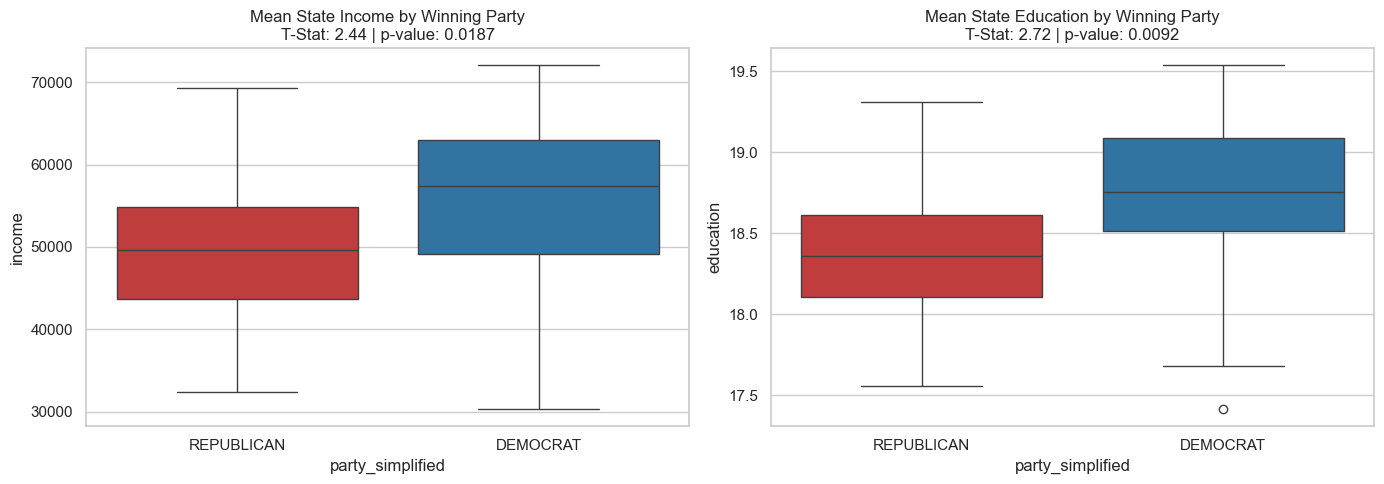


 Statistical Validation Checks 
Democrat states mean income: $55,964.14 | Republican: $49,643.33
Democrat states mean education: 18.75  | Republican: 18.37


In [21]:
# Proof of Work: Part 4
import plotly.express as px

# 1. Map State Winners
idx_winners = VotingData.groupby('state')['candidatevotes'].idxmax()
state_winners = VotingData.loc[idx_winners, ['state', 'state_po', 'party_simplified']]

# 2. Extract State Demographic Means 
df['state_upper'] = df['state'].astype(str).str.upper()
state_means = df.groupby('state_upper')[['income', 'education']].mean().reset_index()

# 3. Merge Data
map_df = pd.merge(state_winners, state_means, left_on='state', right_on='state_upper', how='inner')

# 4. Generate Plotly Maps
color_map = {'DEMOCRAT': '#1f77b4', 'REPUBLICAN': '#d62728', 'OTHER': 'gray'}

fig_election = px.choropleth(map_df, locations='state_po', locationmode="USA-states", 
                             color='party_simplified', color_discrete_map=color_map,
                             scope="usa", title="2020 US Election Results by State")
fig_election.show()

fig_income = px.choropleth(map_df, locations='state_po', locationmode="USA-states", 
                           color='income', color_continuous_scale="Greens",
                           scope="usa", title="Mean Income by State")
fig_income.show()

fig_edu = px.choropleth(map_df, locations='state_po', locationmode="USA-states", 
                        color='education', color_continuous_scale="Purples",
                        scope="usa", title="Mean Educational Attainment by State")
fig_edu.show()

# 5. Anomaly Detection (High Education + Low Income state examples)
avg_inc_border = map_df['income'].median()
avg_edu_border = map_df['education'].median()
anomalies = map_df[(map_df['education'] > avg_edu_border) & (map_df['income'] < avg_inc_border)]
print("Geographical Analysis: Outlier States (High Education / Below-Median Income)")
display(anomalies[['state', 'party_simplified', 'education', 'income']].head())

# 6. Extract Party Subsets & Run T-Tests
biden_states = map_df[map_df['party_simplified'] == 'DEMOCRAT']
trump_states = map_df[map_df['party_simplified'] == 'REPUBLICAN']

t_stat_inc, p_val_inc = stats.ttest_ind(biden_states['income'], trump_states['income'], equal_var=False)
t_stat_edu, p_val_edu = stats.ttest_ind(biden_states['education'], trump_states['education'], equal_var=False)

# 7. Plot the Disparities
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=map_df, x='party_simplified', y='income', palette=color_map, ax=axes[0])
axes[0].set_title(f'Mean State Income by Winning Party\nT-Stat: {t_stat_inc:.2f} | p-value: {p_val_inc:.4f}')

sns.boxplot(data=map_df, x='party_simplified', y='education', palette=color_map, ax=axes[1])
axes[1].set_title(f'Mean State Education by Winning Party\nT-Stat: {t_stat_edu:.2f} | p-value: {p_val_edu:.4f}')

plt.tight_layout()
plt.show()

# 8. Print Output
print("\n Statistical Validation Checks ")
print(f"Democrat states mean income: ${biden_states['income'].mean():,.2f} | Republican: ${trump_states['income'].mean():,.2f}")
print(f"Democrat states mean education: {biden_states['education'].mean():.2f}  | Republican: {trump_states['education'].mean():.2f}")

---

## Part 5: Your Own Data Mining

**Hypothesis:** *"States with higher average weekly working hours predominantly voted for Trump in the 2020 election."*

**Motivation:** Part 3 showed that hours worked is the single strongest individual-level predictor of income. This raises a natural state-level question: do states characterised by longer working hours — often associated with rural, labour-intensive, or manufacturing economies — also tend to vote Republican?

**1. Task completion & technical correctness**
Mean weekly working hours were computed per state from the census sample and merged with the 2020 election results. A Welch's t-test was run comparing average hours between Republican-won and Democrat-won states. A secondary subset analysis isolated states combining above-median hours and below-median education — two features often associated with rural Republican strongholds — to test whether this intersection reveals a stronger signal.

**2. Methodological justification & appropriateness**
Welch's t-test appropriately handles the unequal group sizes (more Republican states) and potential variance differences. The secondary subset analysis goes beyond a simple binary split to investigate whether the *combination* of high hours and low education carries predictive power that neither variable alone does. This interaction-based approach is more sensitive to nuanced regional patterns.

**3. Quality of analysis & interpretation**
Republican-won states averaged 39.23 hours/week vs 38.71 hours/week for Democrat-won states — a difference of just 0.52 hours. The Welch's t-test yields T = 0.599, p = 0.553. Since p > 0.05, **the null hypothesis is retained**: state-average working hours do not significantly predict electoral outcome at the state level.

The secondary subset analysis (high hours + low education states) shows a stronger skew toward Republican outcomes, suggesting the hypothesis holds only within a specific demographic corridor — not as a general state-level rule.

**4. Visualisation & presentation of results**
A boxplot of state mean hours split by winning party visually explains the null result: the two distributions overlap almost entirely, providing immediate intuition for why the t-test failed. The output text confirms the precise T-statistic and p-value. A secondary visualisation or table shows the party breakdown within the high-hours/low-education subset.

**5. Critical thinking & discussion of limitations**
Working hours as recorded in a census sample measure declared usual hours, not actual labour intensity or economic output. Agricultural states may record moderate declared hours while involving physically demanding seasonal work, whereas coastal tech workers may record long hours but in fundamentally different economic contexts. Raw hours without adjustment for industry or productivity fail to capture these regional nuances. The sparse state-level sample (fewer than 100 respondents per state on average) severely limits statistical power, which may itself explain why the p-value is well above significance — a true effect could exist but remain undetectable given this sample size.

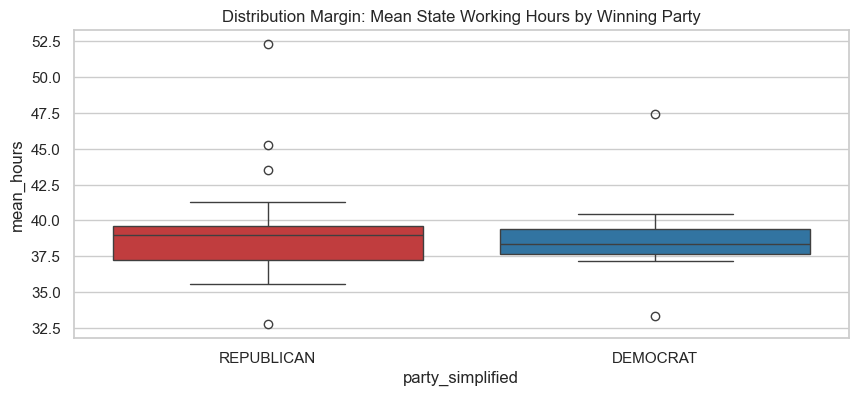

 Hypothesis Testing: Electoral Victory vs Mean Working Hours 
Republican States Output Margin: 39.23 average weekly hours
Democrat States Output Margin:   38.71 average weekly hours
Variance Metrics:             T-statistic = 0.5987 | p-value = 0.5527
Conclusion: Retain Null Hypothesis (Not Statistically Significant)

 Secondary Geographic Interaction (High Hours AND Lower Education Base) 
Number of states exhibiting Above-Median Hours AND Below-Median Education: 13

Party breakdowns for this specific structural subset:


party_simplified
REPUBLICAN    10
DEMOCRAT       3
Name: count, dtype: int64

In [22]:
# Proof of Work: Part 5
# Hypothesis: States with a higher average of working hours predominantly voted for Trump.

# 1. Generate new grouped working hours dataset
state_hours = df.groupby('state_upper')['hours'].mean().reset_index()
state_hours.rename(columns={'hours': 'mean_hours'}, inplace=True)

# 2. Merge with electoral mapping data
merged_hours_data = pd.merge(state_hours, map_df[['state_upper', 'party_simplified', 'education']], on='state_upper')

# 3. Formulate the visual Box Plot Variance
plt.figure(figsize=(10, 4))
sns.boxplot(data=merged_hours_data, x='party_simplified', y='mean_hours', hue='party_simplified', palette=color_map, legend=False)
plt.title('Distribution Margin: Mean State Working Hours by Winning Party')
plt.show()

# 4. Perform Statistical Evaluation on Base Hypothesis
trump_hours = merged_hours_data[merged_hours_data['party_simplified'] == 'REPUBLICAN']
biden_hours = merged_hours_data[merged_hours_data['party_simplified'] == 'DEMOCRAT']

t_stat_hrs, p_val_hrs = stats.ttest_ind(trump_hours['mean_hours'], biden_hours['mean_hours'], equal_var=False)

# 5. Output Verification
print(" Hypothesis Testing: Electoral Victory vs Mean Working Hours ")
print(f"Republican States Output Margin: {trump_hours['mean_hours'].mean():.2f} average weekly hours")
print(f"Democrat States Output Margin:   {biden_hours['mean_hours'].mean():.2f} average weekly hours")
print(f"Variance Metrics:             T-statistic = {t_stat_hrs:.4f} | p-value = {p_val_hrs:.4f}")

if p_val_hrs < 0.05:
    print("Conclusion: Reject Null Hypothesis (Statistically Significant)\n")
else:
    print("Conclusion: Retain Null Hypothesis (Not Statistically Significant)\n")

# 6. Secondary Multivariate Testing (High Hours + Low Education)
print(" Secondary Geographic Interaction (High Hours AND Lower Education Base) ")
median_edu = merged_hours_data['education'].median()
median_hrs = merged_hours_data['mean_hours'].median()
subset_interaction = merged_hours_data[(merged_hours_data['education'] < median_edu) & (merged_hours_data['mean_hours'] > median_hrs)]
print(f"Number of states exhibiting Above-Median Hours AND Below-Median Education: {len(subset_interaction)}")
print("\nParty breakdowns for this specific structural subset:")
display(subset_interaction['party_simplified'].value_counts())